In [ ]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [21]:
class MassEncoding(nn.Module):
	def __init__(self, resolution):
		super().__init__()
		self.a = nn.Parameter(torch.randn(1, resolution))
		self.b = nn.Parameter(torch.randn(1, resolution))
		self.c = nn.Parameter(torch.randn(1, resolution) / resolution)

	def forward(self, x, derivative=False):
		z = self.a * x - self.b
		y = self.c * torch.exp(-z ** 2)
		if derivative:
			return -2 * (self.a * z * y).sum(dim=-1, keepdim=True)
		return y.sum(dim=-1, keepdim=True)
		
	def compose(self, x, k):
		fix = [self(x)]
		dfix = [self(x, 1)]
		for _ in range(k - 1):
			fix.append(self(fix[-1]))
			dfix.append(self(fix[-1], True) * dfix[-1])
		return torch.stack(fix), torch.stack(dfix)

In [27]:
mse_loss = nn.MSELoss()

def loss_fn(f, x):
	fx = f(x)
	dfx = f(x, True)
	return mse_loss(fx, dfx)

# def loss_fn(f, x, k):
#     _, dfx = f.compose(x, k)
#     return mse_loss(dfx[1:], 1.2 * dfx[:-1] + 0.5)

In [28]:
best_device = "cuda" if torch.cuda.is_available() else "cpu"
force_cpu = False
device = best_device if not force_cpu else "cpu"
best_device, device

('cuda', 'cuda')

In [ ]:
num_epochs = 100_000
batch_size = 64
resolution = 64
domain = (0, 5)
size_norm = 1.0
size_norm_weight = 0.001
torch.manual_seed(42)

f = MassEncoding(resolution)
f.to(device)
optimizer = torch.optim.Adam(f.parameters(), lr=1e-3)

for i in range(num_epochs):
    x = torch.rand(batch_size, 1, device=device) * (domain[1] - domain[0]) + domain[0]

    size = f(x).abs().mean()
    size_loss = size_norm_weight * (size - size_norm)**2
    target_loss = loss_fn(f, x)

    optimizer.zero_grad()
    (target_loss + size_loss).backward()
    nn.utils.clip_grad_norm_(f.parameters(), 1.0)
    optimizer.step()

    if i % 500 == 0 or i == num_epochs - 1:   
        print(f"{i:5d}  loss {target_loss.item():.6f}  mean|f| {size.item():.6f}")

    0  loss 0.009612  mean|f| 0.081526
  500  loss 0.000005  mean|f| 0.005627
 1000  loss 0.000005  mean|f| 0.009014
 1500  loss 0.000008  mean|f| 0.014110
 2000  loss 0.000005  mean|f| 0.013473
 2500  loss 0.000016  mean|f| 0.027118
 3000  loss 0.000022  mean|f| 0.035235
 3500  loss 0.000020  mean|f| 0.035345
 4000  loss 0.000034  mean|f| 0.061026
 4500  loss 0.000013  mean|f| 0.040059
 5000  loss 0.000030  mean|f| 0.057362
 5500  loss 0.000027  mean|f| 0.068426
 6000  loss 0.000031  mean|f| 0.068062


KeyboardInterrupt: 

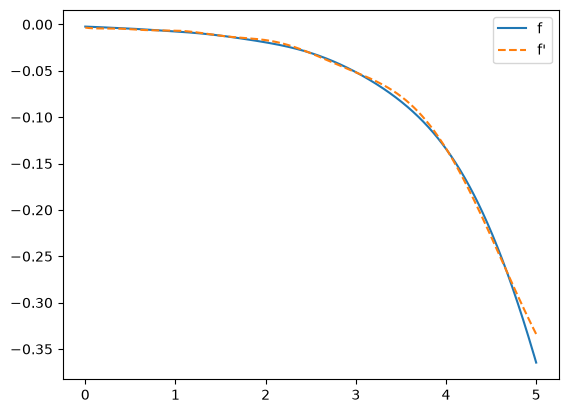

In [31]:
f.cpu()
x = torch.linspace(domain[0], domain[1], 1000).unsqueeze(-1)
with torch.no_grad():
    fx = f(x)
    dfx = f(x, True)
f.to(device)

plt.plot(x, fx, label="f")
plt.plot(x, dfx, "--", label="f'")
# plt.plot(x, d2fx, "--", label="f''")
# plt.plot(x, ffx, "--", label="f^2")

plt.legend()
plt.show()